# кластеризация клиентов

обучение без учителя: делим клиентов на группы по возрасту, стажу, расходам, активности и обращениям
используем standardscaler, k-means, silhouette и pca

## загрузка и признаки

читаем csv и оставляем пять числовых признаков
customerid - идентификатор, он не описывает поведение клиента
y нет, потому что готовых меток кластеров не существует

In [20]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

RANDOM_STATE = 42
df = pd.read_csv("ai_customer_segments_lab6.csv")
features = ["Age", "TenureMonths", "MonthlySpend", "UsageHours", "SupportCalls"]
X = df[features].copy()
print("размер таблицы:", df.shape)
print(df.head())
print(X.describe().round(2))

размер таблицы: (600, 6)
   CustomerId  Age  TenureMonths  MonthlySpend  UsageHours  SupportCalls
0       10001   51            72        3274.0        77.1             4
1       10002   23             8        1607.0        50.8             3
2       10003   21            14        1631.0        22.8             7
3       10004   47            27        3624.0        48.4             0
4       10005   47            29         587.0        21.1             3
          Age  TenureMonths  MonthlySpend  UsageHours  SupportCalls
count  600.00        600.00        600.00      600.00        600.00
mean    37.97         31.62       1984.60       42.08          1.84
std     10.91         17.56       1020.50       23.09          2.19
min     18.00          1.00        377.00        1.00          0.00
25%     30.00         17.00       1085.25       21.90          0.00
50%     37.00         33.00       1848.00       38.70          1.00
75%     45.00         44.25       2742.50       60.85        

## масштабирование

standardscaler приводит признаки к среднему около нуля и отклонению около единицы
диапазоны признаков сильно различаются, поэтому без масштаба k-means будет смотреть почти только на monthlyspend

In [21]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print("диапазоны до масштабирования:")
print((X.max() - X.min()).round(1).to_string())
print("средние после масштабирования:")
print(pd.Series(X_scaled.mean(axis=0)).round(3).to_string())
print("стандартные отклонения:")
print(pd.Series(X_scaled.std(axis=0)).round(3).to_string())

диапазоны до масштабирования:
Age               55.0
TenureMonths      71.0
MonthlySpend    4428.0
UsageHours       105.6
SupportCalls      12.0
средние после масштабирования:
0   -0.0
1    0.0
2    0.0
3   -0.0
4   -0.0
стандартные отклонения:
0    1.0
1    1.0
2    1.0
3    1.0
4    1.0


## выбор числа кластеров

для k от 2 до 8 считаем inertia и silhouette
меньше inertia лучше, silhouette ближе к 1 лучше

лучший silhouette у k = 3, локоть inertia около k = 4
критерии дают неоднозначный ответ, берём k = 4 ради более дробных сегментов

   k   Inertia  Silhouette
0  2  2043.198       0.303
1  3  1430.329       0.337
2  4  1144.795       0.314
3  5  1048.664       0.269
4  6   955.769       0.243
5  7   876.283       0.229
6  8   816.302       0.229


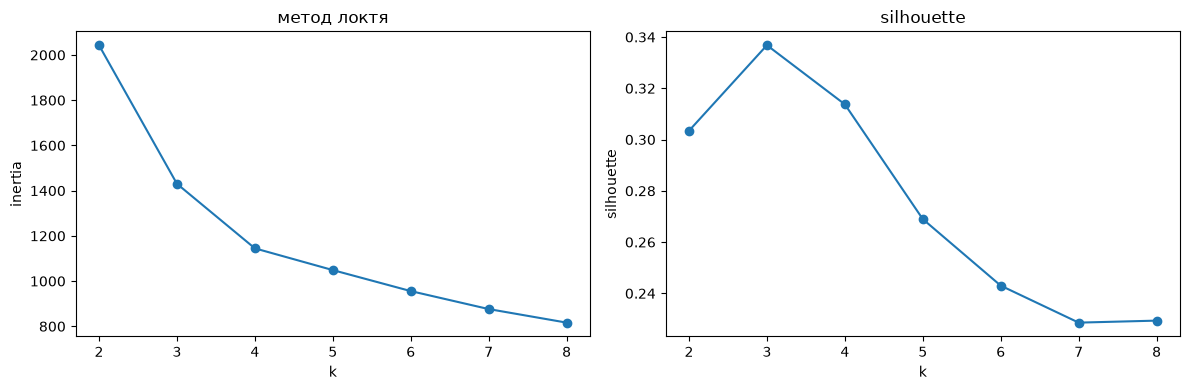

In [22]:
rows = []
for k in range(2, 9):
    model_k = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels_k = model_k.fit_predict(X_scaled)
    row = {"k": k, "Inertia": model_k.inertia_, "Silhouette": silhouette_score(X_scaled, labels_k)}
    rows.append(row)

k_results = pd.DataFrame(rows)
print(k_results.round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(k_results["k"], k_results["Inertia"], marker="o")
axes[0].set_xlabel("k")
axes[0].set_ylabel("inertia")
axes[0].set_title("метод локтя")
axes[1].plot(k_results["k"], k_results["Silhouette"], marker="o")
axes[1].set_xlabel("k")
axes[1].set_ylabel("silhouette")
axes[1].set_title("silhouette")
plt.tight_layout()
plt.show()

## итоговый k-means

обучаем модель с k = 4 и сохраняем метки кластеров для каждого клиента

In [23]:
best_k = 4
kmeans = KMeans(n_clusters=best_k, random_state=RANDOM_STATE, n_init=10)
clusters = kmeans.fit_predict(X_scaled)
result = df.copy()
result["Cluster"] = clusters
print("размеры кластеров:")
print(result["Cluster"].value_counts().sort_index().to_string())
print("первые строки:")
print(result.head().to_string())

размеры кластеров:
Cluster
0    103
1    166
2    162
3    169
первые строки:
   CustomerId  Age  TenureMonths  MonthlySpend  UsageHours  SupportCalls  Cluster
0       10001   51            72        3274.0        77.1             4        1
1       10002   23             8        1607.0        50.8             3        3
2       10003   21            14        1631.0        22.8             7        0
3       10004   47            27        3624.0        48.4             0        1
4       10005   47            29         587.0        21.1             3        2


все кластеры содержат от 103 до 169 клиентов
подозрительно малых групп нет

## профили сегментов

cluster 0 - молодые новички с частыми обращениями
cluster 1 - лояльные активные клиенты с высоким чеком
cluster 2 - старшие экономные клиенты с низкой активностью
cluster 3 - клиенты среднего стажа с умеренной активностью

In [24]:
profile = result.groupby("Cluster")[features].mean().round(1)
profile["Count"] = result["Cluster"].value_counts().sort_index()
profile["Name"] = [
    "молодые новички",
    "лояльные активные",
    "старшие экономные",
    "средний стаж",
]
print(profile.to_string())

          Age  TenureMonths  MonthlySpend  UsageHours  SupportCalls  Count               Name
Cluster                                                                                      
0        31.0          10.6        1793.6        26.7           5.7    103    молодые новички
1        40.3          45.0        3324.2        70.8           1.0    166  лояльные активные
2        46.7          39.3         901.6        19.9           0.8    162  старшие экономные
3        31.5          23.9        1823.4        44.5           1.3    169       средний стаж


## pca

pca сжимает пять признаков в две компоненты
доля дисперсии = сумма explained_variance_ratio_
две компоненты сохраняют около 72 процентов дисперсии
кластеры частично разделены, но их границы пересекаются

доля объяснённой дисперсии: 0.722


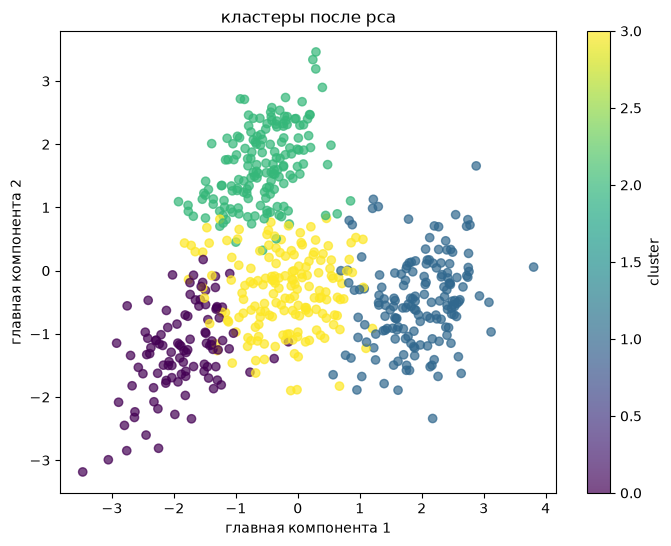

In [25]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
total_var = pca.explained_variance_ratio_.sum()
print("доля объяснённой дисперсии:", round(total_var, 3))
plt.figure(figsize=(8, 6))
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=clusters, alpha=0.7)
plt.xlabel("главная компонента 1")
plt.ylabel("главная компонента 2")
plt.title("кластеры после pca")
plt.colorbar(scatter, label="cluster")
plt.show()

## эксперимент без масштабирования

обучаем k-means на исходных признаках без standardscaler
silhouette без масштаба выше, но кластеры держатся в основном на monthlyspend
высокая метрика не отменяет необходимости понимать, какие признаки задают расстояния

In [26]:
kmeans_raw = KMeans(n_clusters=best_k, random_state=RANDOM_STATE, n_init=10)
raw_labels = kmeans_raw.fit_predict(X)
raw_score = silhouette_score(X, raw_labels)
scaled_score = silhouette_score(X_scaled, clusters)
print("silhouette без масштабирования:", round(raw_score, 3))
print("silhouette с масштабированием:", round(scaled_score, 3))

silhouette без масштабирования: 0.597
silhouette с масштабированием: 0.314


## новые клиенты

новые объекты масштабируем тем же scaler и получаем номер кластера
первый клиент попадает в cluster 0 - молодые новички с частыми обращениями
второй клиент попадает в cluster 1 - лояльные активные клиенты с высоким чеком

In [27]:
new_customers = pd.DataFrame([
    {"Age": 24, "TenureMonths": 4, "MonthlySpend": 1600, "UsageHours": 24, "SupportCalls": 6},
    {"Age": 43, "TenureMonths": 48, "MonthlySpend": 3600, "UsageHours": 78, "SupportCalls": 1},
])
new_scaled = scaler.transform(new_customers)
new_clusters = kmeans.predict(new_scaled)
new_customers["PredictedCluster"] = new_clusters
print(new_customers.to_string())

   Age  TenureMonths  MonthlySpend  UsageHours  SupportCalls  PredictedCluster
0   24             4          1600          24             6                 0
1   43            48          3600          78             1                 1


## альтернативное число кластеров

при k = 3 silhouette выше, а группы крупнее и проще для интерпретации
три сегмента: новички с обращениями, активные лояльные, экономные старшие
при k = 5 появляются более мелкие группы, но silhouette падает
дополнительные группы дробят средний сегмент и хуже отделяются

In [28]:
alt_model_3 = KMeans(n_clusters=3, random_state=RANDOM_STATE, n_init=10)
alt_labels_3 = alt_model_3.fit_predict(X_scaled)
alt_result_3 = df.copy()
alt_result_3["Cluster"] = alt_labels_3
alt_profile_3 = alt_result_3.groupby("Cluster")[features].mean().round(1)
alt_profile_3["Count"] = alt_result_3["Cluster"].value_counts().sort_index()
print("k = 3")
print("silhouette:", round(silhouette_score(X_scaled, alt_labels_3), 3))
print(alt_profile_3.to_string())

alt_model_5 = KMeans(n_clusters=5, random_state=RANDOM_STATE, n_init=10)
alt_labels_5 = alt_model_5.fit_predict(X_scaled)
alt_result_5 = df.copy()
alt_result_5["Cluster"] = alt_labels_5
alt_profile_5 = alt_result_5.groupby("Cluster")[features].mean().round(1)
alt_profile_5["Count"] = alt_result_5["Cluster"].value_counts().sort_index()
print("k = 5")
print("silhouette:", round(silhouette_score(X_scaled, alt_labels_5), 3))
print(alt_profile_5.to_string())

k = 3
silhouette: 0.337
          Age  TenureMonths  MonthlySpend  UsageHours  SupportCalls  Count
Cluster                                                                   
0        30.1          15.4        1803.0        34.5           3.7    208
1        39.1          43.0        3118.9        68.5           0.9    201
2        45.4          37.4         988.7        22.5           0.8    191
k = 5
silhouette: 0.269
          Age  TenureMonths  MonthlySpend  UsageHours  SupportCalls  Count
Cluster                                                                   
0        46.8          40.7         896.6        19.8           0.8    154
1        42.0          44.9        3366.6        72.1           1.0    147
2        29.9          10.7        1774.5        27.5           6.2     87
3        27.1          34.7        2181.5        52.9           1.0     95
4        36.0          16.0        1676.8        35.7           1.7    117


## контрольные вопросы

1. обучение без учителя ищет структуру в данных без готовых меток
2. кластер - группа похожих друг на друга объектов
3. k-means ищет k центроидов и относит объект к ближайшему
4. масштаб важен, иначе крупные по величине признаки доминируют
5. centroid - средняя точка кластера
6. inertia - сумма квадратов расстояний объектов до своих центроидов
7. silhouette - насколько объект ближе к своему кластеру, чем к чужому
8. метод локтя ищет перелом на графике inertia
9. pca снижает размерность и помогает визуализировать данные
10. номера кластеров условны, их смысл задаётся профилями

## итог

кластеризация ищет группы без готовых меток, в отличие от классификации
standardscaler. выбрали k = 4 и получили четыре сегмента.
pca сохранил около 72 процентов дисперсии, границы кластеров пересекаются